In [30]:
from pathlib import Path
import tensorflow as tf
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

In [8]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 4

SPLIT_DATASET_PATH = Path(
    r"D:\py\Eye-Disease-Detection-system\split_dataset"
)

class_names = [
    'normal',
    'cataract',
    'conjunctivitis',
    'pterygium'
]

train_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATASET_PATH / "train",
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATASET_PATH / "val",
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATASET_PATH / "test",
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)


Found 2905 files belonging to 4 classes.
Found 623 files belonging to 4 classes.
Found 623 files belonging to 4 classes.


In [4]:
AUTOTUNE = tf.data.AUTOTUNE

# Improve data loading performance
train_dataset = train_dataset.prefetch(AUTOTUNE)
val_dataset = val_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

In [6]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom((-0.15, 0.10)),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomContrast(0.15),
    tf.keras.layers.RandomBrightness(0.15, value_range=(0, 255)),
], name="augmentation")


In [5]:
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 77s 5us/step


In [9]:
inputs = tf.keras.Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# EfficientNetB0 feature extraction
x = base_model(x, training=False)

# Classification head
x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(x)

x = tf.keras.layers.Dropout(0.4)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB0_EyeDisease"
)

model.summary()

Model: "EfficientNetB0_EyeDisease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,055 (16.08 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
# Model directory
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_efficientnetb0.keras"

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(BEST_MODEL_PATH),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks = [
    checkpoint,
    early_stopping,
    reduce_lr
]

In [12]:
INITIAL_EPOCHS = 15

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=INITIAL_EPOCHS,
    callbacks=callbacks
)

Epoch 1/15


d:\py\Eye-Disease-Detection-system\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 375ms/step - accuracy: 0.7955 - loss: 0.5143
Epoch 1: val_accuracy improved from None to 0.84591, saving model to ..\models\best_efficientnetb0.keras

Epoch 1: finished saving model to ..\models\best_efficientnetb0.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 48s 479ms/step - accuracy: 0.7955 - loss: 0.5143 - val_accuracy: 0.8459 - val_loss: 0.3802 - learning_rate: 0.0010
Epoch 2/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.8995 - loss: 0.2740
Epoch 2: val_accuracy improved from 0.84591 to 0.89406, saving model to ..\models\best_efficientnetb0.keras

Epoch 2: finished saving model to ..\models\best_efficientnetb0.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 37s 408ms/step - accuracy: 0.8995 - loss: 0.2740 - val_accuracy: 0.8941 - val_loss: 0.2699 - learning_rate: 0.0010
Epoch 3/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 344ms/step - accuracy: 0.9263 - loss: 0.2015
Epoch 3: val_accuracy improved from 0.89406 to 0.90690, saving model to ..\models\best_efficientnetb0.keras

Epoch

## Fine Tune 

In [20]:
from pathlib import Path
import tensorflow as tf

MODEL_DIR = Path("../models")

# Original best transfer learning model
BEST_MODEL_PATH = MODEL_DIR / "best_efficientnetb0.keras"

# Separate fine-tuned model path
FINE_TUNED_MODEL_PATH = MODEL_DIR / "best_efficientnetb0_finetuned.keras"

# Load best Stage 1 model
model = tf.keras.models.load_model(
    str(BEST_MODEL_PATH)
)


In [21]:
# Get EfficientNetB0 base model
base_model = model.get_layer("efficientnetb0")

# Unfreeze base model
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Display trainable layer information
print("Total layers:", len(base_model.layers))
print(
    "Trainable layers:",
    sum(1 for layer in base_model.layers if layer.trainable)
)

Total layers: 238
Trainable layers: 23


In [22]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "EfficientNetB0_EyeDisease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,055 (16.08 MB)

 Trainable params: 1,647,844 (6.29 MB)

 Non-trainable params: 2,566,211 (9.79 MB)

In [23]:
fine_tune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(FINE_TUNED_MODEL_PATH),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

fine_tune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

fine_tune_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

fine_tune_callbacks = [
    fine_tune_checkpoint,
    fine_tune_early_stopping,
    fine_tune_reduce_lr
]

In [24]:
FINE_TUNE_EPOCHS = 15

history_fine = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_tune_callbacks
)

Epoch 1/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.9869 - loss: 0.0432
Epoch 1: val_accuracy improved from None to 0.92937, saving model to ..\models\best_efficientnetb0_finetuned.keras

Epoch 1: finished saving model to ..\models\best_efficientnetb0_finetuned.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 55s 550ms/step - accuracy: 0.9869 - loss: 0.0432 - val_accuracy: 0.9294 - val_loss: 0.1846 - learning_rate: 1.0000e-05
Epoch 2/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 394ms/step - accuracy: 0.9917 - loss: 0.0303
Epoch 2: val_accuracy improved from 0.92937 to 0.93419, saving model to ..\models\best_efficientnetb0_finetuned.keras

Epoch 2: finished saving model to ..\models\best_efficientnetb0_finetuned.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 42s 463ms/step - accuracy: 0.9917 - loss: 0.0303 - val_accuracy: 0.9342 - val_loss: 0.1777 - learning_rate: 1.0000e-05
Epoch 3/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.9928 - loss: 0.0292
Epoch 3: val_accuracy improved from 0.93419 to 0.93579,

In [25]:
best_fine_tuned_model = tf.keras.models.load_model(
    str(FINE_TUNED_MODEL_PATH)
)

In [26]:
# Load original best model
original_model = tf.keras.models.load_model(
    str(BEST_MODEL_PATH)
)

# Evaluate original model
original_loss, original_acc = original_model.evaluate(
    val_dataset,
    verbose=0
)

# Evaluate fine-tuned model
fine_loss, fine_acc = best_fine_tuned_model.evaluate(
    val_dataset,
    verbose=0
)

print("\nMODEL COMPARISON")
print("-" * 40)

print(f"Original Model Accuracy   : {original_acc * 100:.2f}%")
print(f"Fine-Tuned Model Accuracy : {fine_acc * 100:.2f}%")

if fine_acc > original_acc:
    print("\nFine-tuning improved validation accuracy!")
else:
    print("\nOriginal model performed equally or better.")


MODEL COMPARISON
----------------------------------------
Original Model Accuracy   : 94.22%
Fine-Tuned Model Accuracy : 95.02%

Fine-tuning improved validation accuracy!


In [27]:
test_loss, test_accuracy = best_fine_tuned_model.evaluate(
    test_dataset,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 305ms/step - accuracy: 0.9358 - loss: 0.2250
Test Accuracy: 93.58%
Test Loss: 0.2250


In [31]:
# Actual labels
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_dataset
])

# Model predictions
y_pred_probs = best_fine_tuned_model.predict(test_dataset)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=test_dataset.class_names,
    digits=4
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 370ms/step
                precision    recall  f1-score   support

        normal     0.9600    0.9091    0.9339       132
      cataract     0.9659    0.9605    0.9632       177
conjunctivitis     0.9235    0.9330    0.9282       194
     pterygium     0.8889    0.9333    0.9106       120

      accuracy                         0.9358       623
     macro avg     0.9346    0.9340    0.9339       623
  weighted avg     0.9366    0.9358    0.9359       623



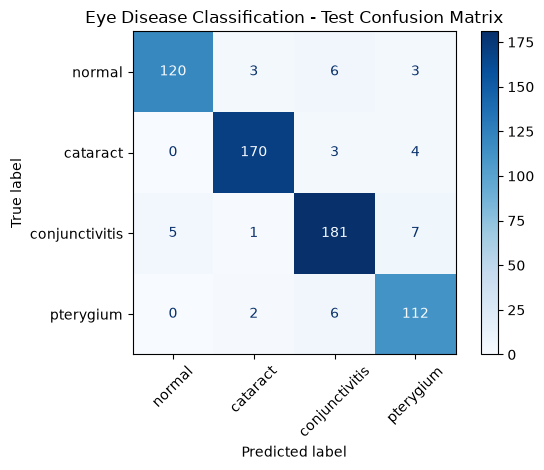

In [32]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(4)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.class_names
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Eye Disease Classification - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [33]:
Path("../results").mkdir(parents=True, exist_ok=True)

results = pd.DataFrame({
    "Metric": ["Test Accuracy", "Test Loss"],
    "Value": [test_accuracy, test_loss]
})

results.to_csv("../results/experiment2_test_results.csv", index=False)